# №1-3

1. Ознакомьтесь с набором данных mpg из библиотеки Seaborn.
(загрузка через df = sns.load_dataset(’mpg’))
2. Посчитайте количество строк и столбцов.
3. Проведите разведочный анализ, то есть:
### a) для каждой числовой переменной вычислите:
* Долю пропусков
* Максимальное и минимальное значение
* Среднее значение
* Медиану
* Дисперсию
* Квантиль 0.1 и 0.9
* Квартиль 1 и 3
### b) для каждой категориальной переменной вычислите:
* Долю пропусков
* Количество уникальных значений
* Моду

In [3]:
import pandas as pd
import seaborn as sns

# 1. Загрузка и первичное знакомство с набором данных
df = sns.load_dataset('mpg')

print("Первые 5 строк датасета:")
print(df.head())
print("\nОбщая информация о данных:")
df.info()

# 2. Количество строк и столбцов
rows, cols = df.shape
print(f"\nКоличество строк: {rows}")
print(f"Количество столбцов: {cols}")

# 3. Разведочный анализ (EDA)

# Разделяем столбцы на числовые и категориальные
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(exclude='number').columns

# Анализ числовых переменных
num_stats = pd.DataFrame({
    'Доля пропусков': df[num_cols].isna().mean(),
    'Минимум': df[num_cols].min(),
    'Максимум': df[num_cols].max(),
    'Среднее': df[num_cols].mean(),
    'Медиана': df[num_cols].median(),
    'Дисперсия': df[num_cols].var(),
    'Квантиль 0.1': df[num_cols].quantile(0.1),
    'Квантиль 0.9': df[num_cols].quantile(0.9),
    'Квартиль 1 (0.25)': df[num_cols].quantile(0.25),
    'Квартиль 3 (0.75)': df[num_cols].quantile(0.75),
})

print("\n\n==== #3 (a) Статистика по числовым переменным ====")
print(num_stats.round(4).to_string())

# Анализ категориальных переменных
cat_stats_list = []
for col in cat_cols:
    modes = df[col].mode().tolist()
    mode_str = ', '.join(map(str, modes)) if modes else None

    cat_stats_list.append({
        'Переменная': col,
        'Доля пропусков': df[col].isna().mean(),
        'Уникальных значений': df[col].nunique(dropna=True),
        'Мода': mode_str
    })

cat_stats = pd.DataFrame(cat_stats_list).set_index('Переменная')

print("\n\n==== #3 (b) Статистика по категориальным переменным ====")
print(cat_stats.to_string())

Первые 5 строк датасета:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  

Общая информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1  

# №4
Сформулируйте и проверьте минимум 2 статистические
гипотезы. Выбор критериев для проверки гипотез требуется обосновать.
Сделать выводы в терминах предметной области.

In [5]:
from itertools import combinations
import pandas as pd
import seaborn as sns
from scipy import stats

df = sns.load_dataset('mpg')
alpha = 0.05

print("Информация о переменной origin")
origin_counts = df['origin'].value_counts(dropna=False)
print("Частоты категорий:")
print(origin_counts)

regions = df['origin'].dropna().unique().tolist()
print(f"\nОбнаруженные категории: {regions}")
print(f"Минимальный размер группы: {origin_counts.min()}")

print("\n==== гипотеза: Влияние региона производства на mpg ====")

# Формируем выборки динамически на основе найденных категорий
groups = [df.loc[df['origin'] == r, 'mpg'].dropna() for r in regions]

# Проверка предпосылок (нормальность и равенство дисперсий)
print("\nОписательные статистики и тест Шапиро–Уилка по группам:")
for r, g in zip(regions, groups):
    stat_sw, p_sw = stats.shapiro(g)
    print(f"  {r:8s} (n={len(g):3d}): W = {stat_sw:.4f}, p = {p_sw:.6f}, медиана = {g.median():.2f}")

stat_lev, p_lev = stats.levene(*groups)
print(f"\nТест Левена (равенство дисперсий): F = {stat_lev:.4f}, p-value = {p_lev:.6f}")

stat_kw, p_kw = stats.kruskal(*groups)
print(f"\nКритерий Краскела–Уоллиса: H = {stat_kw:.4f}, p-value = {p_kw:.6e}")

if p_kw < alpha:
    print("Отвергаем H0. Распределения mpg статистически значимо различаются между категориями.")

    # попарный U-критерий Манна–Уитни
    pairs = list(combinations(range(len(regions)), 2))
    m = len(pairs)
    print(f"\nPost-hoc анализ (Манна–Уитни, m = {m}):")

    for i, j in pairs:
        u_stat, p_mw = stats.mannwhitneyu(groups[i], groups[j], alternative='two-sided')
        p_adj = min(p_mw * m, 1.0)
        signif = "Значимо" if p_adj < alpha else "Не значимо"
        print(f"  {regions[i]:8s} vs {regions[j]:8s}: U = {u_stat:.1f}, "
              f"p_raw = {p_mw:.6e}, p_adj = {p_adj:.6e} ({signif})")
else:
    print("Нет оснований отвергнуть H0.")


print("\n=== гипотеза 2: Взаимосвязь weight и mpg ===")

df_clean = df[['weight', 'mpg']].dropna()

# Проверка нормальности обеих переменных
_, p_sw_w = stats.shapiro(df_clean['weight'])
_, p_sw_m = stats.shapiro(df_clean['mpg'])
print(f"Шапиро–Уилк: p_weight = {p_sw_w:.6e}, p_mpg = {p_sw_m:.6e}")

# Корреляция Спирмена
rho, p_sp = stats.spearmanr(df_clean['weight'], df_clean['mpg'])
print(f"\nКоэффициент корреляции Спирмена: rho = {rho:.4f}, p-value = {p_sp:.6e}")

if p_sp < alpha:
    direction = "отрицательная (обратная)" if rho < 0 else "положительная (прямая)"
    print(f"Вывод: Отвергаем H0. Выявлена статистически значимая {direction} связь.")
else:
    print("Вывод: Нет оснований отвергнуть H0.")

Информация о переменной origin
Частоты категорий:
origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

Обнаруженные категории: ['usa', 'japan', 'europe']
Минимальный размер группы: 70

==== гипотеза: Влияние региона производства на mpg ====

Описательные статистики и тест Шапиро–Уилка по группам:
  usa      (n=249): W = 0.9376, p = 0.000000, медиана = 18.50
  japan    (n= 79): W = 0.9797, p = 0.241967, медиана = 31.60
  europe   (n= 70): W = 0.9512, p = 0.008405, медиана = 26.50

Тест Левена (равенство дисперсий): F = 0.0999, p-value = 0.904917

Критерий Краскела–Уоллиса: H = 134.4567, p-value = 6.354883e-30
Отвергаем H0. Распределения mpg статистически значимо различаются между категориями.

Post-hoc анализ (Манна–Уитни, m = 3):
  usa      vs japan   : U = 2499.5, p_raw = 1.634245e-23, p_adj = 4.902735e-23 (Значимо)
  usa      vs europe  : U = 3353.0, p_raw = 3.596499e-15, p_adj = 1.078950e-14 (Значимо)
  japan    vs europe  : U = 3503.0, p_raw = 5.010500e-03, p

Выводы:
Предварительно через value_counts проверили столбец origin: в данных присутствуют три категории (usa, europe, japan), и в каждой из них достаточно наблюдений для анализа.

1) **Зависимость топливной экономичности от страны производства.**
- H0: значения mpg у автомобилей из США, Европы и Японии не различаются.
- H1: хотя бы в одной группе экономичность отличается.
- Выбор критерия: сравниваются три независимые выборки. Классический дисперсионный анализ (ANOVA) не подходит, так как тест Шапиро-Уилка показал отклонение от нормального распределения, тест Левена - неравенство дисперсий, а объемы групп сильно различаются. Поэтому выбран непараметрический критерий Краскела-Уоллиса, а для попарного сравнения стран - критерий Манна-Уитни с поправкой Бонферрони.
- Вывод: при p < 0.05 гипотеза H0 отвергается. Автомобили из США статистически значимо менее экономичны, чем европейские и японские.
2) **Связь между массой автомобиля и экономичностью.**
- H0: статистическая связь между массой (weight) и экономичностью (mpg) отсутствует.
- H1: связь между признаками существует.
- Выбор критерия: применен коэффициент ранговой корреляции Спирмена вместо корреляции Пирсона, поскольку оба признака распределены ненормально (по тесту Шапиро-Уилка), а зависимость между ними носит нелинейный характер.
- Вывод: при p < 0.05 гипотеза H0 отвергается. Выявлена сильная отрицательная связь: чем больше масса автомобиля, тем меньше миль он проезжает на одном галлоне, так как на разгон и движение более тяжелой машины затрачивается больше топлива.

# №5-6

5. Закодируйте категориальные переменные, необходимые для
анализа, если требуется. Методом OneHotEncoding или LabelEncoding.
6. Постройте таблицу корреляции признаков и целевого столбца.
Обоснуйте, какой столбец является целевым, а какие признаками.

Первые 5 строк после кодирования:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year  origin_europe  origin_japan  origin_usa  
0          70              0             0           1  
1          70              0             0           1  
2          70              0             0           1  
3          70              0             0           1  
4          70              0             0           1  

Корреляция признаков с целевым столбцом 'mpg' (Спирмен):
                  mpg
model_year     0.5735
origin_japan   0.4428
acceleration   0.4387
origin_europe  0.2657
origin_usa    -0.5740
cylinders    

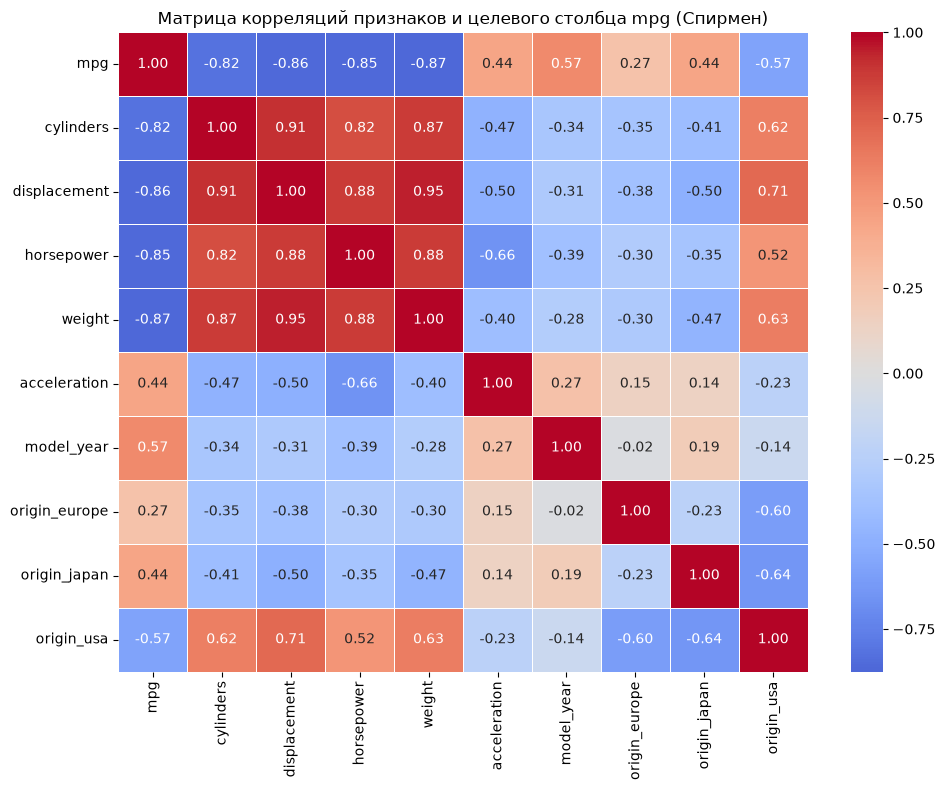

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = sns.load_dataset('mpg')

df_encoded = df.drop(columns=['name'])

# Применить One-Hot Encoding к origin
df_encoded = pd.get_dummies(df_encoded, columns=['origin'], dtype=int)

print("Первые 5 строк после кодирования:")
print(df_encoded.head())

# корреляция Спирмена т.к. нелинейность и ненорм распределений
corr_matrix = df_encoded.corr(method='spearman')

# Отдельная таблица корреляции признаков с целевым столбцом mpg
target_corr = (
    corr_matrix[['mpg']]
    .drop(index='mpg')
    .sort_values(by='mpg', ascending=False)
)

print("\nКорреляция признаков с целевым столбцом 'mpg' (Спирмен):")
print(target_corr.round(4))

print("\nПолная матрица корреляции:")
print(corr_matrix.round(3).to_string())

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Матрица корреляций признаков и целевого столбца mpg (Спирмен)')
plt.tight_layout()
plt.show()